<a href="https://colab.research.google.com/github/irfanefedonmez/ml-campus_data_project-colab/blob/main/project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Campus Walk Dataset Analysis

This notebook prepares our campus observations for further analysis. I check the raw data, clean the values, encode the categories and choose features for clustering. Scaling, correlation, clustering and interpretation.

## 1. Data Loading
### 1.1 Importing Libraries

In [4]:
import pandas as pd
from IPython.display import display
import numpy as np

# Pandas is used to load and work with the dataset.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
df = pd.read_csv(
    '/content/drive/MyDrive/Project/CampusWalkDataset_TemplateIDs.csv',
    skiprows=4
)

In [7]:
from IPython.display import display
print("Dataset shape:", df.shape)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


Dataset shape: (994, 27)


## 2. Data Cleaning


### 2.1 Removing Empty Rows and Unnamed Columns

In [8]:

# Remove completely empty rows and columns left over from the CSV template.
df = df.dropna(how='all').dropna(axis=1, how='all').copy()
df = df.loc[:, ~df.columns.str.startswith('Unnamed:')]

# The Excel template also contains rows with only a recorder ID.
# I remove these unfinished rows because they have no observation date.
df = df.dropna(subset=['date']).reset_index(drop=True)

# Keep the original answers to compare with the encoded values later.
raw_df = df.copy()
# Keep the written observations separately so I can use them when interpreting clusters.
observation_notes = df[[
    'recorder_id', 'date', 'location', 'most_notable_nature_element', 'other_notes'
]].copy()

print('Shape after removing empty data:', df.shape)
display(df.head())


Shape after removing empty data: (135, 23)


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0.0,1.0,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0.0,2.0,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10.0,20.0,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0.0,2.0,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0.0,0.0,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN


### 2.2 Cleaning Temperature and Count Columns

In [9]:
# Temperature values sometimes contain a C or extra spaces.
temperature_cols = [col for col in df.columns if 'temp' in col.lower()]
for col in temperature_cols:
    cleaned = df[col].astype('string').str.replace('°C', '', regex=False)
    cleaned = cleaned.str.replace('C', '', case=False, regex=False).str.strip()
    df[col] = pd.to_numeric(cleaned, errors='coerce')

# Make sure the insect and bird counts are numeric as well.
for col in ['insects_count', 'birds_count']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

display(df[temperature_cols + [c for c in ['insects_count', 'birds_count'] if c in df]].head())

,temperature_c,insects_count,birds_count
0,16.0,0.0,1.0
1,16.0,0.0,2.0
2,16.0,10.0,20.0
3,16.0,0.0,2.0
4,16.0,0.0,0.0


### 2.3 Making Text Categories Consistent

In [10]:
# Use lowercase and remove extra spaces to avoid treating the same answer
# as different categories (for example 'Sunny' and 'sunny').
text_columns = [
    'location', 'weather', 'sound level', 'foot_traffic',
    'trees_presence', 'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence', 'moss_or_lichen_presence',
    'wellbeing_rating', 'ease_rating', 'stress_rating',
    'nature_connection_experience_rating',
    'primary_sound_type_urban', 'other_sound_type_urban',
    'primary_sound_type_nature', 'other_sound_type_nature',
    'most_notable_nature_element',
]
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype('string').str.lower().str.strip()
        df[col] = df[col].replace({'': pd.NA, 'nan': pd.NA})

print('Weather categories:', df['weather'].dropna().unique())
print('Sound level categories:', df['sound level'].dropna().unique())

Weather categories: <StringArray>
['partly cloudy', 'sunny', 'windy', 'cloudy']
Length: 4, dtype: string
Sound level categories: <StringArray>
['quiet', 'moderate', 'loud']
Length: 3, dtype: string


### 2.4 Removing Columns Not Needed for Clustering

In [11]:
# I keep IDs, dates and written notes for interpretation, not as model features.
# One-hot encoding every free-text note would create too many sparse columns.
columns_to_drop = [
    'recorder_id', 'date', 'other_notes', 'most_notable_nature_element',
]
df = df.drop(columns=columns_to_drop, errors='ignore')

print('Remaining columns:', len(df.columns))

Remaining columns: 19


## 3. Data Encoding

I use ordinal encoding for answers with a meaningful order, and one-hot encoding for categories that do not have a natural order.

### 3.1 Sound Level and Foot Traffic — Ordinal Encoding

In [12]:
# Higher numbers mean louder sound or more foot traffic.
sound_map = {'quiet': 0, 'moderate': 1, 'loud': 2}
traffic_map = {'none': 0, 'low': 0, 'moderate': 1, 'high': 2}

df['sound level'] = df['sound level'].map(sound_map)
df['foot_traffic'] = df['foot_traffic'].map(traffic_map)

display(df[['sound level', 'foot_traffic']].head(10))

,sound level,foot_traffic
0,0,0
1,1,0
2,0,0
3,1,0
4,1,0
5,1,0
6,1,0
7,1,0
8,0,0
9,0,0


### 3.2 Tree and Plant Presence — Ordinal Encoding

In [13]:
# Turn the ordered presence categories into numeric values.
tree_map = {'none': 0, 'one or two': 1, 'many': 2}
plant_map = {'none': 0, 'some': 1, 'many': 2}

df['trees_presence'] = df['trees_presence'].map(tree_map)
plant_columns = [
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence',
]
for col in plant_columns:
    df[col] = df[col].map(plant_map)

display(df[['trees_presence'] + plant_columns].head(10))

,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence
0,2.0,1.0,1.0,1.0
1,2.0,NaN,1.0,NaN
2,2.0,NaN,2.0,1.0
3,1.0,1.0,NaN,1.0
4,1.0,NaN,1.0,NaN
5,2.0,1.0,1.0,2.0
6,2.0,1.0,2.0,1.0
7,2.0,2.0,2.0,2.0
8,2.0,2.0,2.0,1.0
9,2.0,2.0,2.0,1.0


### 3.3 Wellbeing, Ease, Stress and Nature Connection — Ordinal Encoding

In [14]:
# These rating scales have an order, so I assign numbers in that order.
wellbeing_map = {
    'very low wellbeing': 0, 'low wellbeing': 1, 'neutral': 2,
    'positive wellbeing': 3, 'very positive wellbeing': 4,
}
ease_map = {
    'very uneasy': 0, 'slighly uneasy': 1, 'slightly uneasy': 1,
    'neutral': 2, 'easy': 3, 'vey easy': 4, 'very easy': 4,
}
stress_map = {
    'very stressful': 0, 'stressful': 1, 'neutral': 2,
    'mostly calm': 3, 'very calm': 4,
}
nature_connection_map = {
    'less connected': 0, 'no change': 1, 'same': 1,
    'a little more connected': 2, 'much more connected': 3,
}

rating_maps = {
    'wellbeing_rating': wellbeing_map,
    'ease_rating': ease_map,
    'stress_rating': stress_map,
    'nature_connection_experience_rating': nature_connection_map,
}
for col, mapping in rating_maps.items():
    df[col] = df[col].map(mapping)

display(df[list(rating_maps)].head(10))

,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,3,2,1,0
1,3,2,2,2
2,3,3,3,1
3,3,2,2,3
4,3,3,3,0
5,3,3,3,2
6,2,2,4,1
7,3,4,3,3
8,2,2,4,0
9,4,4,4,3


### 3.4 Weather and Location — One-Hot Encoding

In [15]:
# Weather and locations are names, not ranked values.
# Each category gets its own 0/1 column.
for col in ['weather', 'location']:
    df[col] = df[col].fillna('missing')
df = pd.get_dummies(df, columns=['weather', 'location'], dtype=int)

weather_location_cols = [
    col for col in df if col.startswith(('weather_', 'location_'))
]
display(df[weather_location_cols].head())

,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,location_l01 mainentrance,location_l02 librarygreen,location_l03 lowersidepathihub,location_l04 pathfrontihub,location_l05 greenfrontsportscentre,location_l06 hedgingbehindsportscentre,location_l07 carparknearsportscentre,location_l08 accessroadnearsportscentre,location_l10 otheroffcampus
0,0,1,0,0,1,0,0,0,0,0,0,0,0
1,0,0,1,0,0,1,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,1,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,1,0
4,0,0,1,0,0,0,0,0,0,1,0,0,0


### 3.5 Urban and Nature Sound Types — One-Hot Encoding

In [16]:
# Different sound types are not ranked, so I use one-hot encoding again.
sound_type_cols = [
    'primary_sound_type_urban', 'other_sound_type_urban',
    'primary_sound_type_nature', 'other_sound_type_nature',
]
for col in sound_type_cols:
    df[col] = df[col].fillna('missing')
df = pd.get_dummies(df, columns=sound_type_cols, dtype=int)

sound_dummy_cols = [
    col for col in df if any(col.startswith(name + '_') for name in sound_type_cols)
]
display(df[sound_dummy_cols].head())

,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_missing,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic,primary_sound_type_nature_insects,primary_sound_type_nature_other,primary_sound_type_nature_other birds,primary_sound_type_nature_seagulls,primary_sound_type_nature_trees,primary_sound_type_nature_wind,other_sound_type_nature_insects,other_sound_type_nature_missing,other_sound_type_nature_other,other_sound_type_nature_other birds,other_sound_type_nature_seagulls,other_sound_type_nature_trees,other_sound_type_nature_wind
0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0
1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0
3,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0
4,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0


### 3.6 Removing Unnecessary Data

I removed the most_notable_nature_element column in the cleaning section because it contains written descriptions with many different answers. These values are not suitable for the clustering process, so I decided not to encode them.

### 3.7 Handling Missing Numeric Values

In [17]:
# After encoding, fill remaining missing numeric values with each column's median.
# I leave missing observations as missing until this step instead of
# assuming that missing plant or traffic records mean zero.
numeric_cols = df.select_dtypes(include='number').columns
print('Missing values before filling:', int(df.isna().sum().sum()))
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

remaining_non_numeric = df.select_dtypes(exclude='number').columns.tolist()
remaining_missing = int(df.isna().sum().sum())
print('Non-numeric columns:', remaining_non_numeric)
print('Remaining missing values:', remaining_missing)
print('Final dataset shape:', df.shape)

assert not remaining_non_numeric, 'Some text columns still need encoding.'
assert remaining_missing == 0, 'Some missing values still need attention.'
display(df.head(10))

Missing values before filling: 91
Non-numeric columns: []
Remaining missing values: 0
Final dataset shape: (135, 50)


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,location_l01 mainentrance,location_l02 librarygreen,location_l03 lowersidepathihub,location_l04 pathfrontihub,location_l05 greenfrontsportscentre,location_l06 hedgingbehindsportscentre,location_l07 carparknearsportscentre,location_l08 accessroadnearsportscentre,location_l10 otheroffcampus,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_missing,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic,primary_sound_type_nature_insects,primary_sound_type_nature_other,primary_sound_type_nature_other birds,primary_sound_type_nature_seagulls,primary_sound_type_nature_trees,primary_sound_type_nature_wind,other_sound_type_nature_insects,other_sound_type_nature_missing,other_sound_type_nature_other,other_sound_type_nature_other birds,other_sound_type_nature_seagulls,other_sound_type_nature_trees,other_sound_type_nature_wind
0,16.0,0,0,0.0,1.0,2.0,1.0,1.0,1.0,3,2,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0
1,16.0,1,0,0.0,2.0,2.0,1.0,1.0,1.0,3,2,2,2,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2,16.0,0,0,10.0,20.0,2.0,1.0,2.0,1.0,3,3,3,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0
3,16.0,1,0,0.0,2.0,1.0,1.0,1.0,1.0,3,2,2,3,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0
4,16.0,1,0,0.0,0.0,1.0,1.0,1.0,1.0,3,3,3,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
5,17.0,1,0,2.0,4.0,2.0,1.0,1.0,2.0,3,3,3,2,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0
6,17.0,1,0,2.0,2.0,2.0,1.0,2.0,1.0,2,2,4,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
7,19.0,1,0,7.0,0.0,2.0,2.0,2.0,2.0,3,4,3,3,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0
8,16.0,0,0,3.0,1.0,2.0,2.0,2.0,1.0,2,2,4,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
9,18.0,0,0,6.0,2.0,2.0,2.0,2.0,1.0,4,4,4,3,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0


## 4. Checking the Encoded Data

### 4.1 Comparing Original and Encoded Ratings

In [18]:
# Compare the original answers with the converted numbers to check the mappings.
audit_columns = [
    'foot_traffic', 'trees_presence',
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence', 'wellbeing_rating',
    'ease_rating', 'stress_rating',
    'nature_connection_experience_rating',
]
audit_df = pd.DataFrame(index=df.index)
for col in audit_columns:
    audit_df['Original: ' + col] = raw_df[col]
    audit_df['Encoded: ' + col] = df[col]

display(audit_df.head(15))

,Original: foot_traffic,Encoded: foot_traffic,Original: trees_presence,Encoded: trees_presence,Original: native_or_wild_plant_presence,Encoded: native_or_wild_plant_presence,Original: ornnamental_or_planted_plant_presence,Encoded: ornnamental_or_planted_plant_presence,Original: moss_or_lichen_presence,Encoded: moss_or_lichen_presence,Original: wellbeing_rating,Encoded: wellbeing_rating,Original: ease_rating,Encoded: ease_rating,Original: stress_rating,Encoded: stress_rating,Original: nature_connection_experience_rating,Encoded: nature_connection_experience_rating
0,Low,0,Many,2.0,Some,1.0,Some,1.0,Some,1.0,Positive wellbeing,3,Neutral,2,Stressful,1,Less connected,0
1,Low,0,Many,2.0,NaN,1.0,Some,1.0,NaN,1.0,Positive wellbeing,3,Neutral,2,Neutral,2,A little more connected,2
2,Low,0,Many,2.0,NaN,1.0,Many,2.0,Some,1.0,Positive wellbeing,3,Easy,3,Mostly calm,3,No change,1
3,Low,0,One or two,1.0,Some,1.0,NaN,1.0,Some,1.0,Positive wellbeing,3,Neutral,2,Neutral,2,Much more connected,3
4,Low,0,One or two,1.0,NaN,1.0,Some,1.0,NaN,1.0,Positive wellbeing,3,Easy,3,Mostly calm,3,Less connected,0
5,Low,0,Many,2.0,Some,1.0,Some,1.0,Many,2.0,Positive wellbeing,3,Easy,3,Mostly calm,3,A little more connected,2
6,Low,0,Many,2.0,Some,1.0,Many,2.0,Some,1.0,Neutral,2,Neutral,2,Very calm,4,No change,1
7,Low,0,Many,2.0,Many,2.0,Many,2.0,Many,2.0,Positive wellbeing,3,Vey easy,4,Mostly calm,3,Much more connected,3
8,Low,0,Many,2.0,Many,2.0,Many,2.0,Some,1.0,Neutral,2,Neutral,2,Very calm,4,Less connected,0
9,Low,0,Many,2.0,Many,2.0,Many,2.0,Some,1.0,Very positive wellbeing,4,Vey easy,4,Very calm,4,Much more connected,3


### 4.2 Checking the Prepared Dataset

In [19]:
# Take one last look at the columns and dataset size.
print('Rows and columns:', df.shape)
print('Total missing values:', int(df.isna().sum().sum()))
display(df.head())

Rows and columns: (135, 50)
Total missing values: 0


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,location_l01 mainentrance,location_l02 librarygreen,location_l03 lowersidepathihub,location_l04 pathfrontihub,location_l05 greenfrontsportscentre,location_l06 hedgingbehindsportscentre,location_l07 carparknearsportscentre,location_l08 accessroadnearsportscentre,location_l10 otheroffcampus,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_missing,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic,primary_sound_type_nature_insects,primary_sound_type_nature_other,primary_sound_type_nature_other birds,primary_sound_type_nature_seagulls,primary_sound_type_nature_trees,primary_sound_type_nature_wind,other_sound_type_nature_insects,other_sound_type_nature_missing,other_sound_type_nature_other,other_sound_type_nature_other birds,other_sound_type_nature_seagulls,other_sound_type_nature_trees,other_sound_type_nature_wind
0,16.0,0,0,0.0,1.0,2.0,1.0,1.0,1.0,3,2,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0
1,16.0,1,0,0.0,2.0,2.0,1.0,1.0,1.0,3,2,2,2,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2,16.0,0,0,10.0,20.0,2.0,1.0,2.0,1.0,3,3,3,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0
3,16.0,1,0,0.0,2.0,1.0,1.0,1.0,1.0,3,2,2,3,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0
4,16.0,1,0,0.0,0.0,1.0,1.0,1.0,1.0,3,3,3,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0


## 5. Data Scaling

I used StandardScaler to scale the numerical features. This helps prevent features with larger values from having more influence on clustering. I kept the one-hot encoded columns as 0 and 1.

In [21]:
from sklearn.preprocessing import StandardScaler

# Make a copy of the dataset before scaling.
df_scaled = df.copy()

# Select numerical columns, but leave one-hot encoded columns unchanged.
scale_cols = [
    'temperature_c',
    'sound level',
    'foot_traffic',
    'insects_count',
    'birds_count',
    'trees_presence',
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence',
    'wellbeing_rating',
    'ease_rating',
    'stress_rating',
    'nature_connection_experience_rating'
]

scale_cols = [col for col in scale_cols if col in df_scaled.columns]

# Apply StandardScaler to the selected columns.
scaler = StandardScaler()
df_scaled[scale_cols] = scaler.fit_transform(df_scaled[scale_cols])

# Compare the values before and after scaling.
print("Before scaling:")
display(df[scale_cols].head())

print("After scaling:")
display(df_scaled[scale_cols].head())


Before scaling:


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,16.0,0,0,0.0,1.0,2.0,1.0,1.0,1.0,3,2,1,0
1,16.0,1,0,0.0,2.0,2.0,1.0,1.0,1.0,3,2,2,2
2,16.0,0,0,10.0,20.0,2.0,1.0,2.0,1.0,3,3,3,1
3,16.0,1,0,0.0,2.0,1.0,1.0,1.0,1.0,3,2,2,3
4,16.0,1,0,0.0,0.0,1.0,1.0,1.0,1.0,3,3,3,0


After scaling:


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
0,-0.483562,-1.022948,-0.587805,-0.537246,-0.357106,0.523053,-0.707107,-0.614452,-0.580201,0.37497,-0.704598,-2.104730,-1.489025
1,-0.483562,0.446180,-0.587805,-0.537246,0.002665,0.523053,-0.707107,-0.614452,-0.580201,0.37497,-0.704598,-0.944981,0.425436
2,-0.483562,-1.022948,-0.587805,1.428288,6.478545,0.523053,-0.707107,1.627467,-0.580201,0.37497,0.388744,0.214768,-0.531795
3,-0.483562,0.446180,-0.587805,-0.537246,0.002665,-1.911851,-0.707107,-0.614452,-0.580201,0.37497,-0.704598,-0.944981,1.382666
4,-0.483562,0.446180,-0.587805,-0.537246,-0.716877,-1.911851,-0.707107,-0.614452,-0.580201,0.37497,0.388744,0.214768,-1.489025


## 6. Correlation Analysis

I used a correlation matrix to check the relationships between numerical features. This helps me understand which variables have positive or negative relationships. I also used a heatmap to make the results easier to see.

###6.1 Correlation Matrix

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the main numerical features for correlation analysis.
correlation_cols = [
    'temperature_c',
    'sound level',
    'foot_traffic',
    'insects_count',
    'birds_count',
    'trees_presence',
    'wellbeing_rating',
    'ease_rating',
    'stress_rating',
    'nature_connection_experience_rating'
]

correlation_cols = [col for col in correlation_cols if col in df.columns]

# Calculate the correlation between the selected features.
correlation_matrix = df[correlation_cols].corr()

# Display the correlation matrix.
display(correlation_matrix.round(2))


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating
temperature_c,1.00,0.05,0.06,-0.04,-0.04,-0.07,0.18,0.13,0.10,0.14
sound level,0.05,1.00,0.54,-0.24,-0.04,0.16,-0.11,-0.23,-0.23,-0.20
foot_traffic,0.06,0.54,1.00,-0.12,0.07,0.14,-0.02,-0.14,-0.12,-0.17
insects_count,-0.04,-0.24,-0.12,1.00,0.43,-0.05,0.13,0.14,0.05,0.03
birds_count,-0.04,-0.04,0.07,0.43,1.00,-0.07,0.12,0.04,0.06,0.01
trees_presence,-0.07,0.16,0.14,-0.05,-0.07,1.00,0.04,0.03,-0.01,0.04
wellbeing_rating,0.18,-0.11,-0.02,0.13,0.12,0.04,1.00,0.63,0.61,0.57
ease_rating,0.13,-0.23,-0.14,0.14,0.04,0.03,0.63,1.00,0.69,0.43
stress_rating,0.10,-0.23,-0.12,0.05,0.06,-0.01,0.61,0.69,1.00,0.45
nature_connection_experience_rating,0.14,-0.20,-0.17,0.03,0.01,0.04,0.57,0.43,0.45,1.00


###6.2 Correlation Heatmap

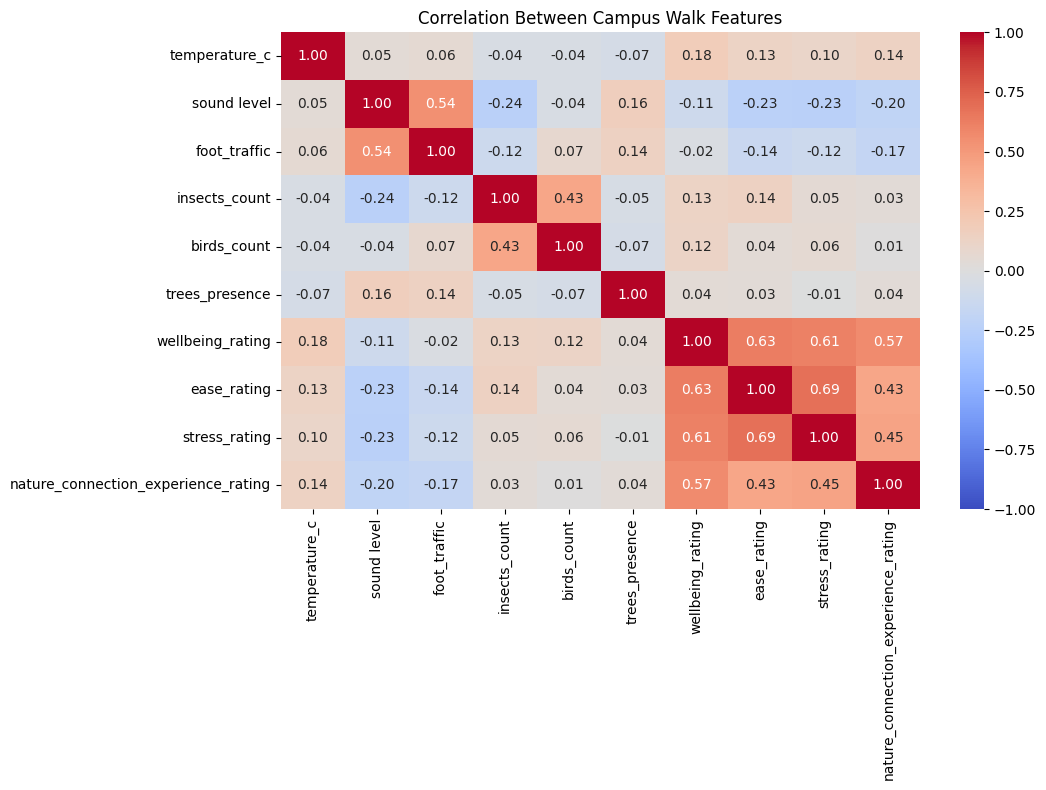

In [23]:
# Create a heatmap to show the correlations more clearly.
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Between Campus Walk Features')
plt.tight_layout()
plt.show()


## 7. Clustering

### 7.1 Selecting Features for Clustering

In [24]:
# Try different sets of features depending on what I want to study.
feature_sets = {
    'nature_urban': [
        'nature_connection_experience_rating', 'trees_presence',
        'primary_sound_type_urban', 'other_sound_type_urban',
    ],
    'wellbeing_encounters': [
        'wellbeing_rating', 'ease_rating', 'stress_rating',
    ],
}

selected_theme = 'nature_urban'
selected_features = []
for feature in feature_sets[selected_theme]:
    if feature in df.columns:
        selected_features.append(feature)
    else:
        # One-hot encoded variables now have several columns with this prefix.
        selected_features.extend(
            col for col in df.columns if col.startswith(feature + '_')
        )

if not selected_features:
    raise ValueError('No features found for the selected theme.')

df_clustering = df_scaled[selected_features].copy()
print('Selected theme:', selected_theme)
print('Number of features:', len(selected_features))
print('Selected features:', selected_features)
display(df_clustering.head(10))

Selected theme: nature_urban
Number of features: 13
Selected features: ['nature_connection_experience_rating', 'trees_presence', 'primary_sound_type_urban_construction', 'primary_sound_type_urban_human voices', 'primary_sound_type_urban_other', 'primary_sound_type_urban_service machinery', 'primary_sound_type_urban_traffic', 'other_sound_type_urban_construction', 'other_sound_type_urban_human voices', 'other_sound_type_urban_missing', 'other_sound_type_urban_other', 'other_sound_type_urban_service machinery', 'other_sound_type_urban_traffic']


,nature_connection_experience_rating,trees_presence,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_missing,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic
0,-1.489025,0.523053,0,1,0,0,0,0,0,0,0,0,1
1,0.425436,0.523053,0,0,0,0,1,0,1,0,0,0,0
2,-0.531795,0.523053,1,0,0,0,0,0,0,0,0,0,1
3,1.382666,-1.911851,0,1,0,0,0,0,1,0,0,0,0
4,-1.489025,-1.911851,0,0,0,0,1,0,0,0,1,0,0
5,0.425436,0.523053,0,0,0,0,1,0,1,0,0,0,0
6,-0.531795,0.523053,0,0,0,0,1,0,0,0,1,0,0
7,1.382666,0.523053,0,0,0,0,1,0,0,0,0,1,0
8,-1.489025,0.523053,0,0,0,0,1,0,1,0,0,0,0
9,1.382666,0.523053,0,0,0,1,0,0,0,0,0,0,1


### 7.2 Finding the Number of Clusters

I used the Elbow Method and Silhouette Score to compare different numbers of clusters. This helps me choose a suitable number of groups before running K-Means.



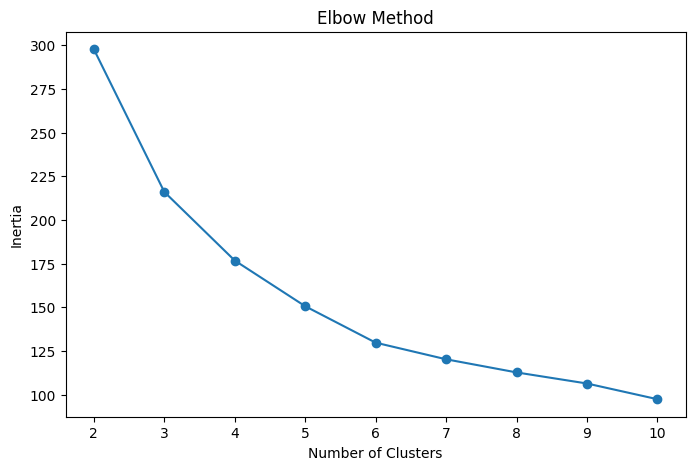

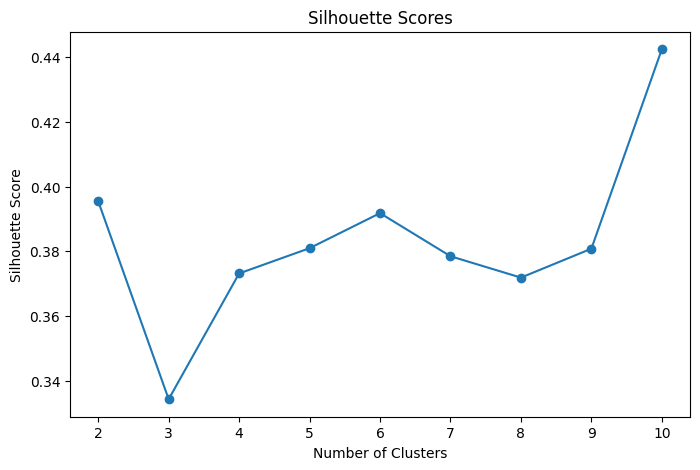

Best number of clusters based on silhouette score: 10


In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Test different numbers of clusters.
k_values = range(2, min(10, len(df_clustering) - 1) + 1)

inertia_values = []
silhouette_values = []

for k in k_values:
    # Create a K-Means model for each number of clusters.
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(df_clustering)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(df_clustering, labels)
    )

# Show the Elbow Method results.
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

# Show the Silhouette Score results.
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores')
plt.show()

# Find the number of clusters with the highest silhouette score.
best_k = list(k_values)[silhouette_values.index(max(silhouette_values))]

print('Best number of clusters based on silhouette score:', best_k)


### 7.3 Running Clustering

I used K-Means to group similar campus observations. I used the number of clusters selected in the previous step and added the cluster labels to the dataset.



In [26]:
# Run K-Means using the selected number of clusters.
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(df_clustering)

# Add the cluster labels to a copy of the original prepared dataset.
df_results = df.copy()
df_results['cluster'] = cluster_labels

# Check how many observations are in each cluster.
print('Number of observations in each cluster:')
print(df_results['cluster'].value_counts().sort_index())

# Display the first 10 observations with their cluster labels.
display(df_results.head(10))


Number of observations in each cluster:
cluster
0     7
1    11
2    15
3    10
4    17
5     8
6    11
7    21
8    18
9    17
Name: count, dtype: int64


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,location_l01 mainentrance,location_l02 librarygreen,location_l03 lowersidepathihub,location_l04 pathfrontihub,location_l05 greenfrontsportscentre,location_l06 hedgingbehindsportscentre,location_l07 carparknearsportscentre,location_l08 accessroadnearsportscentre,location_l10 otheroffcampus,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_missing,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic,primary_sound_type_nature_insects,primary_sound_type_nature_other,primary_sound_type_nature_other birds,primary_sound_type_nature_seagulls,primary_sound_type_nature_trees,primary_sound_type_nature_wind,other_sound_type_nature_insects,other_sound_type_nature_missing,other_sound_type_nature_other,other_sound_type_nature_other birds,other_sound_type_nature_seagulls,other_sound_type_nature_trees,other_sound_type_nature_wind,cluster
0,16.0,0,0,0.0,1.0,2.0,1.0,1.0,1.0,3,2,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,4
1,16.0,1,0,0.0,2.0,2.0,1.0,1.0,1.0,3,2,2,2,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,7
2,16.0,0,0,10.0,20.0,2.0,1.0,2.0,1.0,3,3,3,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,4
3,16.0,1,0,0.0,2.0,1.0,1.0,1.0,1.0,3,2,2,3,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,3
4,16.0,1,0,0.0,0.0,1.0,1.0,1.0,1.0,3,3,3,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1
5,17.0,1,0,2.0,4.0,2.0,1.0,1.0,2.0,3,3,3,2,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,7
6,17.0,1,0,2.0,2.0,2.0,1.0,2.0,1.0,2,2,4,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,2
7,19.0,1,0,7.0,0.0,2.0,2.0,2.0,2.0,3,4,3,3,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0
8,16.0,0,0,3.0,1.0,2.0,2.0,2.0,1.0,2,2,4,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,9
9,18.0,0,0,6.0,2.0,2.0,2.0,2.0,1.0,4,4,4,3,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,8


## 8. Interpreting the Results

I compared the average values of the main features in each cluster. This helps me understand the differences between the groups and identify patterns in the campus observations.

###8.1 Cluster Comparison

In [27]:
# Compare the average values of the selected features in each cluster.
cluster_summary = df_results.groupby('cluster')[selected_features].mean()

print('Average feature values for each cluster:')
display(cluster_summary.round(2))

# Check the number of observations in each cluster.
cluster_sizes = df_results.groupby('cluster').size()

print('Cluster sizes:')
display(cluster_sizes)


Average feature values for each cluster:


,nature_connection_experience_rating,trees_presence,primary_sound_type_urban_construction,primary_sound_type_urban_human voices,primary_sound_type_urban_other,primary_sound_type_urban_service machinery,primary_sound_type_urban_traffic,other_sound_type_urban_construction,other_sound_type_urban_human voices,other_sound_type_urban_missing,other_sound_type_urban_other,other_sound_type_urban_service machinery,other_sound_type_urban_traffic
cluster,,,,,,,,,,,,,
0,2.71,2.0,0.00,0.00,0.00,0.00,1.00,0.14,0.00,0.00,0.57,0.29,0.00
1,0.45,1.0,0.09,0.09,0.09,0.00,0.73,0.00,0.55,0.00,0.36,0.00,0.09
2,1.00,2.0,0.00,0.00,0.07,0.00,0.93,0.13,0.73,0.00,0.13,0.00,0.00
3,2.60,1.0,0.50,0.20,0.00,0.00,0.30,0.00,0.60,0.00,0.20,0.20,0.00
4,0.82,2.0,0.18,0.82,0.00,0.00,0.00,0.00,0.00,0.00,0.18,0.06,0.76
5,1.50,1.0,0.12,0.75,0.00,0.12,0.00,0.00,0.00,0.12,0.00,0.00,0.88
6,3.00,2.0,0.00,0.00,0.18,0.00,0.82,0.00,1.00,0.00,0.00,0.00,0.00
7,2.00,2.0,0.00,0.05,0.00,0.00,0.95,0.00,1.00,0.00,0.00,0.00,0.00
8,2.44,2.0,0.00,0.67,0.00,0.17,0.17,0.00,0.00,0.11,0.06,0.00,0.83


Cluster sizes:


,0
cluster,
0,7
1,11
2,15
3,10
4,17
5,8
6,11
7,21
8,18


###8.2 Cluster Heatmap

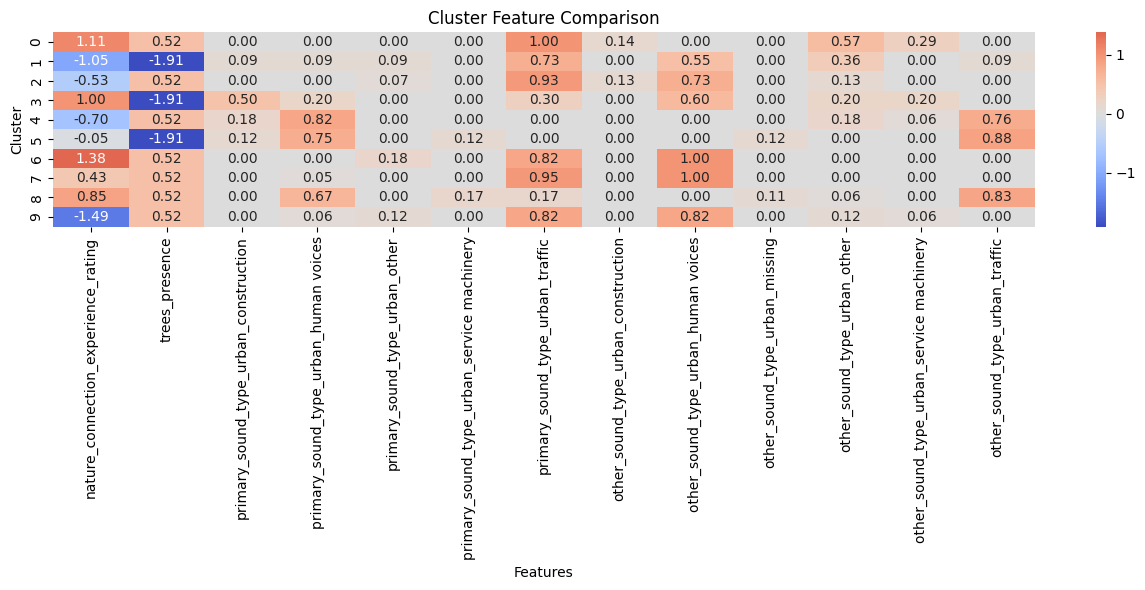

In [28]:
import seaborn as sns

# Use scaled feature values to compare the cluster profiles.
scaled_results = df_clustering.copy()
scaled_results['cluster'] = cluster_labels

scaled_summary = scaled_results.groupby('cluster').mean()

# Create a heatmap to compare the clusters.
plt.figure(figsize=(13, 6))

sns.heatmap(
    scaled_summary,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Cluster Feature Comparison')
plt.xlabel('Features')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()
